# RAG Evaluation con RAGas

## Lo que vamos a hacer

1. Construir un mini-RAG sobre 3 papers de arxiv (los mismos del módulo de RAG)
2. **Generar un golden dataset sintético** con LLM (preguntas + respuestas a partir del corpus)
3. Ejecutar el RAG sobre el dataset
4. **Evaluar con RAGas** las 4 métricas: faithfulness, answer relevancy, context precision, context recall
5. Visualizar resultados
6. Discutir cómo interpretar y mejorar

## Stack

- `ragas>=0.2`
- `langchain>=0.3` · `langchain-chroma` · `langchain-openai`
- `gpt-5-mini` para el RAG · `gpt-5` para generar el golden dataset · `text-embedding-3-small` para embeddings
- `gpt-4.1-mini` como juez (LLM-as-judge de RAGas): RAGas fija una temperature baja para juzgar y los modelos de razonamiento (`gpt-5*`) solo aceptan la de por defecto

## Setup

In [1]:
# ragas fijado a una versión reciente: las antiguas (0.1.x) importan langchain_community.chat_models.vertexai,
# que el langchain-community actual ya no incluye. Si ves ese error, reinicia el runtime tras instalar.
%pip install -q "ragas>=0.2.14,<1" langchain langchain-core langchain-community langchain-openai langchain-chroma openai pypdf chromadb tiktoken requests datasets pandas matplotlib

In [2]:
import os, getpass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

## 1. Mini-RAG · 3 papers de arxiv

Reusamos los mismos papers que en `04-RAG end-to-end.ipynb` del módulo de RAG para que la evaluación sea comparable: Attention · RAG · Self-RAG.

In [3]:
import requests
from pathlib import Path

CORPUS_DIR = Path("./ragas_corpus")
CORPUS_DIR.mkdir(exist_ok=True)

PAPERS = {
    "attention.pdf": "https://arxiv.org/pdf/1706.03762.pdf",
    "rag.pdf":       "https://arxiv.org/pdf/2005.11401.pdf",
    "selfrag.pdf":   "https://arxiv.org/pdf/2310.11511.pdf",
}

for name, url in PAPERS.items():
    dest = CORPUS_DIR / name
    if not dest.exists():
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        r.raise_for_status()
        dest.write_bytes(r.content)
    print(f"  ✓ {name}")

  ✓ attention.pdf
  ✓ rag.pdf
  ✓ selfrag.pdf


In [4]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma

all_docs = []

for name in PAPERS:
    pages = PyPDFLoader(
        str(CORPUS_DIR / name)
    ).load()[:5]

    for p in pages:
        p.metadata["source"] = name

    all_docs.extend(pages)

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
)

chunks = splitter.split_documents(all_docs)

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=OpenAIEmbeddings(
        model="text-embedding-3-small"
    ),
    collection_name="ragas_eval",
)

retriever = vectorstore.as_retriever(
    search_kwargs={"k": 4}
)

print(f"✓ {len(chunks)} chunks indexados")

/tmp/ipykernel_53349/3097178076.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


✓ 75 chunks indexados


### Cadena RAG · LCEL clásica

In [5]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

llm = ChatOpenAI(model="gpt-5-mini")
prompt = ChatPromptTemplate.from_template(
    "Responde a la pregunta usando solo el contexto.\n\n"
    "Contexto:\n{context}\n\nPregunta: {question}"
)

def format_docs(docs):
    return "\n\n".join(d.page_content for d in docs)

rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

# Smoke test
print(rag_chain.invoke("What is multi-head attention?"))

Multi-head attention es un mecanismo que consiste en varios heads de atención ejecutándose en paralelo, que permite al modelo atender conjuntamente a información de distintos subespacios de representación en diferentes posiciones. Matemáticamente:

- cada head se calcula como headi = Attention(QW_Qi, KW_Ki, V W_Vi) (proyecciones lineales de Q, K, V);
- los outputs de los h heads se concatenan y se proyectan: MultiHead(Q, K, V) = Concat(head1, ..., headh) W_O.

En el trabajo se emplean h = 8 heads con dk = dv = d_model/h = 64; debido a la menor dimensión por head, el coste computacional total es similar al de una atención de una sola cabeza con dimensionalidad completa.


## 2. Golden dataset sintético · structured output

Para evaluar necesitamos pares `(pregunta, respuesta esperada)` de referencia. Curarlos a mano es lento; usamos un LLM más capaz para **generar** preguntas y respuestas a partir de los chunks del corpus.

**Patrón moderno**: usamos `with_structured_output` con un esquema Pydantic. El LLM no puede salirse del formato (más fiable que parsear JSON a mano).

In [6]:
from pydantic import BaseModel, Field
import random

class QAPair(BaseModel):
    question: str = Field(description="a specific question that can be answered using the context")
    answer: str = Field(description="a concise, factually correct answer based on the context")

qa_generator = ChatOpenAI(model="gpt-5").with_structured_output(QAPair)

qa_prompt = ChatPromptTemplate.from_template(
    "You are a NLP professor creating an exam. Given the context, generate a SPECIFIC "
    "question (not generic) and its concise factual answer. Avoid 'what is the topic' "
    "style questions.\n\nContext:\n{context}"
)
qa_chain = qa_prompt | qa_generator

random.seed(42)
sample_chunks = random.sample(chunks, 15)  # 15 chunks aleatorios

golden = []
for c in sample_chunks:
    try:
        qa = qa_chain.invoke({"context": c.page_content})
        golden.append({
            "question": qa.question,
            "ground_truth": qa.answer,
            "context_source": c.metadata.get("source"),
        })
    except Exception as e:
        print(f"  ⚠ skip: {e}")

print(f"  ✓ golden dataset · {len(golden)} pares\n")
for q in golden[:3]:
    print(f"  Q: {q['question']}")
    print(f"  A: {q['ground_truth']}\n")

  ✓ golden dataset · 15 pares

  Q: Write the scaled dot-product attention equation used to compute outputs from Q, K, and V, including the scaling term.
  A: Attention(Q, K, V) = softmax((Q K^T) / sqrt(d_k)) V.

  Q: According to the context, which two researchers spent countless long days designing and implementing tensor2tensor, and what outcomes did this bring compared to the earlier codebase?
  A: Lukasz and Aidan; tensor2tensor replaced the earlier codebase, greatly improved results, and massively accelerated the research.

  Q: During training, which components of the RAG system are fine-tuned versus kept fixed, and what is the stated reason for not updating the fixed component?
  A: They keep the document encoder BERTd and the index fixed, and only fine-tune the query encoder BERTq and the BART generator. Updating BERTd is avoided because it would require periodically rebuilding the document index (as in REALM), which is costly and deemed unnecessary for strong performance.



## 3. Ejecutar el RAG sobre el dataset

Para cada pregunta del golden dataset, ejecutamos el RAG y guardamos:

- la pregunta
- la respuesta del RAG
- los chunks recuperados (necesarios para context precision/recall)
- la respuesta esperada (ground truth)

In [7]:
from tqdm import tqdm

rag_dataset = []
for item in tqdm(golden):
    docs = retriever.invoke(item["question"])
    answer = rag_chain.invoke(item["question"])
    rag_dataset.append({
        "user_input": item["question"],
        "response": answer,
        "retrieved_contexts": [d.page_content for d in docs],
        "reference": item["ground_truth"],
    })

print(f"  ✓ ejecutado RAG sobre {len(rag_dataset)} preguntas")

100%|██████████| 15/15 [01:02<00:00,  4.13s/it]

  ✓ ejecutado RAG sobre 15 preguntas


## 4. Evaluar con RAGas · 4 métricas

RAGas usa un LLM como juez. Cada métrica usa un prompt distinto que el LLM evalúa.

| Métrica | Qué mide |
|---|---|
| **Faithfulness** | ¿La respuesta se ciñe a los chunks? (no alucina) |
| **Answer relevancy** | ¿La respuesta responde a la pregunta? |
| **Context precision** | ¿Qué % de los chunks recuperados son relevantes? |
| **Context recall** | ¿Los chunks cubren la info necesaria? |

**Nota de versiones (ragas 0.4.3, octubre 2026)**: usamos la API clásica de `ragas.evaluate()` con `LangchainLLMWrapper`. Funciona, pero al importar verás `DeprecationWarning`: ragas anuncia que en la v1.0 estas métricas pasan a `ragas.metrics.collections` y los wrappers de LangChain a `llm_factory` / `embedding_factory`. Por eso el `%pip install` fija `ragas<1`. Además, ragas 0.4.3 todavía importa un módulo de Vertex AI que `langchain-community` ya no incluye: de ahí el parche de la celda siguiente.

In [8]:
# PARCHE de compatibilidad ragas <-> langchain-community
# (esta versión de ragas importa rutas de Vertex AI que langchain-community ya no incluye;
#  como usamos OpenAI, creamos módulos dummy para que el import de ragas no falle)
import sys, types

_vmod = types.ModuleType("langchain_community.chat_models.vertexai")
class _DummyVertex:
    def __init__(self, *a, **k):
        raise NotImplementedError("Vertex AI no se usa en este lab (usamos OpenAI)")
_vmod.ChatVertexAI = _DummyVertex
sys.modules["langchain_community.chat_models.vertexai"] = _vmod

import langchain_community.llms as _llms
if not hasattr(_llms, "VertexAI"):
    _llms.VertexAI = _DummyVertex

print("parche aplicado · ya puedes ejecutar el import de ragas")


parche aplicado · ya puedes ejecutar el import de ragas


In [9]:
from datasets import Dataset
from ragas import evaluate, EvaluationDataset
from ragas.metrics import (
    Faithfulness,
    AnswerRelevancy,
    LLMContextPrecisionWithReference,
    LLMContextRecall,
)
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper

# Juez de RAGAS: modelo NO de razonamiento. RAGAS baja la temperature para juzgar de forma estable,
# y los modelos de razonamiento (gpt-5*) solo aceptan temperature=1 -> 400. gpt-4.1-mini sí la admite.
judge_llm = LangchainLLMWrapper(ChatOpenAI(model="gpt-4.1-mini"))
judge_emb = LangchainEmbeddingsWrapper(OpenAIEmbeddings(model="text-embedding-3-small"))

eval_dataset = EvaluationDataset.from_list(rag_dataset)

result = evaluate(
    dataset=eval_dataset,
    metrics=[
        Faithfulness(),
        AnswerRelevancy(),
        LLMContextPrecisionWithReference(),
        LLMContextRecall(),
    ],
    llm=judge_llm,
    embeddings=judge_emb,
)

df = result.to_pandas()
df.head()

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_53349/684503290.py:3: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import (
/tmp/ipykernel_53349/684503290.py:3: DeprecationWarning: Importing AnswerRelevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import AnswerRelevancy
  from ragas.metrics import (
/tmp/ipykernel_53349/684503290.py:3: DeprecationWarning: Importing LLMContextPrecisionWithReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.met

,user_input,retrieved_contexts,response,reference,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall
0,Write the scaled dot-product attention equatio...,[into a matrix Q. The keys and values are also...,"Attention(Q, K, V) = softmax(QK^T / √dk) V","Attention(Q, K, V) = softmax((Q K^T) / sqrt(d_...",1.000000,0.453343,1.0,1.0
1,"According to the context, which two researcher...",[efficient inference and visualizations. Lukas...,Lukasz y Aidan; reemplazaron el código anterio...,Lukasz and Aidan; tensor2tensor replaced the e...,1.000000,0.374561,1.0,1.0
2,"During training, which components of the RAG s...",[generation guided by reflections tokens to fu...,"- Fine-tuned: el critic (modelo C), que se ent...",They keep the document encoder BERTd and the i...,0.818182,0.482454,0.0,0.0
3,Give the top-K marginalization formulas for pR...,"[the complete sequence. Technically, it treats...",pRAG-Sequence(y|x) ≈\n∑_{z∈top-k(p(·|x))} pη(z...,pRAG-Sequence(y|x) ≈ sum_{z ∈ top-k(p(·|x))} p...,1.000000,0.699675,1.0,1.0
4,"In FEVER fact verification, how close do the R...","[Wikipedia, or whether there is not enough inf...",Se quedan a 4.3% de los modelos de pipeline de...,Within 4.3% of state-of-the-art.,1.000000,0.530628,0.5,1.0


## 5. Resultados agregados

In [10]:
import pandas as pd
import numpy as np

metric_cols = [
    c for c in df.columns
    if c not in (
        "user_input",
        "response",
        "retrieved_contexts",
        "reference",
    )
]

summary = (
    df[metric_cols]
    .mean(numeric_only=True)
    .fillna(0)
    .sort_values(ascending=False)
)

print("Promedio por métrica:\n")

for m, v in summary.items():
    bar = "█" * int(v * 20)
    print(f"  {m:35s} {v:.3f}  {bar}")

Promedio por métrica:

  faithfulness                        0.971  ███████████████████
  context_recall                      0.867  █████████████████
  llm_context_precision_with_reference 0.798  ███████████████
  answer_relevancy                    0.514  ██████████


### Visualización

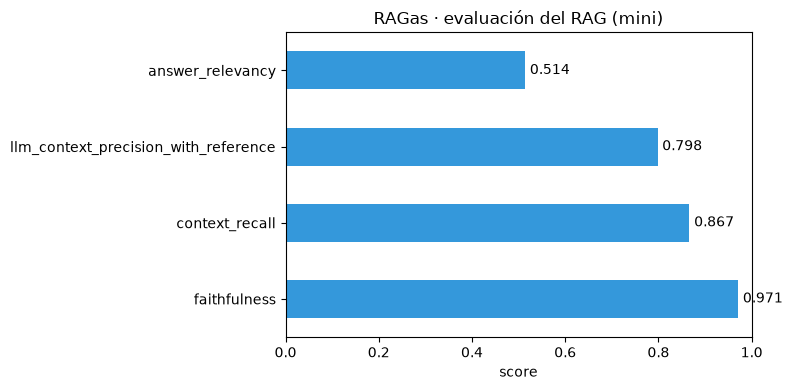

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
summary.plot.barh(ax=ax, color="#3498db")
ax.set_xlim(0, 1)
ax.set_xlabel("score")
ax.set_title("RAGas · evaluación del RAG (mini)")
for i, v in enumerate(summary.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.show()

## 6. ¿Cómo interpretar?

| Si baja… | Sospecha en… |
|---|---|
| **Faithfulness** | El prompt deja al LLM rellenar huecos · sé más estricto |
| **Answer relevancy** | El LLM divaga · prompt más directo (con `gpt-5-mini` no hay temperature que bajar) |
| **Context precision** | El retriever trae ruido · sube k? mejor reranker? |
| **Context recall** | El retriever no encuentra todo · chunking, embedder, hybrid search |

**Ojo con answer relevancy** (sale en torno a 0,5 en nuestra ejecución aunque las respuestas son correctas): la métrica genera preguntas a partir de la respuesta y mide la similitud coseno de sus embeddings con la pregunta original. Lo medimos en octubre de 2026 con las mismas 15 preguntas:

- Responder en inglés (el idioma de las preguntas del golden) en vez de en español solo sube la media de 0,618 a 0,648: el idioma pesa poco.
- Con golden datasets regenerados, la misma configuración dio 0,51, 0,53 y 0,62: hay bastante ruido.
- Pesa más el estilo: preguntas del golden largas y compuestas frente a respuestas cortas. Además, ragas pide 3 preguntas por respuesta y aquí recibe 1 (el aviso `LLM returned 1 generations instead of requested 3`), lo que añade varianza.

Úsala para **comparar variantes del mismo sistema** con el mismo golden, no como nota absoluta.

**Patrón productivo**:

1. Mide → identifica la métrica más baja
2. Hipotetiza → ¿retrieval o generation?
3. Cambia una variable a la vez (chunk size, k, prompt, modelo)
4. Mide de nuevo → ¿mejoró?
5. **Sin medir, todo cambio es opinión**

## Cierre

- RAGas calcula 4 métricas con LLM-as-judge · sin etiquetar a mano
- El **golden dataset** se puede generar sintéticamente con structured output
- Las 4 métricas localizan el problema en retrieval o generation
- En el módulo de Observabilidad (clase 6) llevamos esto a **continuo** con Langfuse, no como batch puntual